# Method 3: Genetic Algorithm
A population of grids evolves by selection, crossover and mutation.
Each individual is the list of numbers in the free cells. Fitness = 1/(1 + energy).

In [28]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Problem
The magic constant, the 2N+2 lines, and a check for a finished square.

In [29]:
def magic_constant(n):
    return n * (n * n + 1) // 2


In [30]:
def get_lines(n):
    rows = [[i * n + j for j in range(n)] for i in range(n)]
    cols = [[i * n + j for i in range(n)] for j in range(n)]
    diag = [i * n + i for i in range(n)]
    anti = [i * n + (n - 1 - i) for i in range(n)]
    return rows + cols + [diag, anti]


In [31]:
def is_magic(square):
    square = np.array(square)
    n = len(square)
    flat = square.flatten()
    if sorted(flat.tolist()) != list(range(1, n * n + 1)):
        return False
    M = magic_constant(n)
    return all(flat[line].sum() == M for line in get_lines(n))


## Test puzzles
We take a known magic square, rotate or flip it, and keep a few cells as givens.

In [32]:
def siamese(n):
    sq = np.zeros((n, n), dtype=int)
    i, j = 0, n // 2
    for v in range(1, n * n + 1):
        sq[i, j] = v
        if sq[(i - 1) % n, (j + 1) % n] == 0:
            i, j = (i - 1) % n, (j + 1) % n
        else:
            i = (i + 1) % n
    return sq


In [6]:
def doubly_even(n):
    sq = np.arange(1, n * n + 1).reshape(n, n)
    for i in range(n):
        for j in range(n):
            if (i % 4 in (0, 3)) == (j % 4 in (0, 3)):
                sq[i, j] = n * n + 1 - sq[i, j]
    return sq


In [7]:
def singly_even(n):
    h = n // 2
    a = siamese(h)
    sq = np.block([[a, a + 2 * h * h], [a + 3 * h * h, a + h * h]])
    k = (n - 2) // 4
    for i in range(h):
        cols = list(range(k)) + list(range(n - k + 1, n))
        if i == h // 2:
            cols = [c + 1 if c < k else c for c in cols]
        for j in cols:
            sq[i, j], sq[i + h, j] = sq[i + h, j], sq[i, j]
    return sq


In [8]:
def make_puzzle(n, n_given=0, seed=None):
    rng = np.random.default_rng(seed)
    if n % 2 == 1:
        sol = siamese(n)
    elif n % 4 == 0:
        sol = doubly_even(n)
    else:
        sol = singly_even(n)
    sol = np.rot90(sol, rng.integers(4))
    if rng.random() < 0.5:
        sol = np.fliplr(sol)
    sol = np.array(sol)
    puzzle = np.zeros((n, n), dtype=int)
    cells = rng.choice(n * n, size=n_given, replace=False)
    puzzle.flat[cells] = sol.flat[cells]
    return puzzle


## Checking the givens
Invalid givens (a repeated value, or a value outside 1…N²) are rejected before the search.

In [9]:
def check_givens(puzzle):
    puzzle = np.array(puzzle)
    n = len(puzzle)
    if puzzle.ndim != 2 or puzzle.shape[1] != n:
        return False
    given = puzzle[puzzle != 0].tolist()
    in_range = all(1 <= v <= n * n for v in given)
    return in_range and len(given) == len(set(given))

## Fitness and operators
Crossover cuts two parents and swaps the right parts. Mutation swaps two positions.

In [10]:
def energies(pop, base, free, A, M):
    full = np.tile(base, (len(pop), 1))
    full[:, free] = pop
    return np.abs(full @ A.T - M).sum(axis=1)


In [11]:
def repair(child, values, rng):

    seen, dup = set(), []
    for i, v in enumerate(child):
        if v in seen:
            dup.append(i)
        else:
            seen.add(v)
    missing = [v for v in values if v not in seen]
    rng.shuffle(missing)
    for i, v in zip(dup, missing):
        child[i] = v
    return child


In [12]:
def crossover(p1, p2, values, rng):
    point = rng.integers(1, len(p1))
    c1 = np.concatenate([p1[:point], p2[point:]])
    c2 = np.concatenate([p2[:point], p1[point:]])
    return repair(c1, values, rng), repair(c2, values, rng)


In [13]:
def mutate(child, rng):
    i, j = rng.choice(len(child), 2, replace=False)
    child[i], child[j] = child[j], child[i]


## Genetic algorithm
Roulette wheel selection, crossover with probability 0.9, mutation with probability 0.3.
If nothing improves for 300 generations, we start again with a new population.

In [14]:
def genetic_algorithm(puzzle, pop_size=200, pc=0.9, pm=0.3, stall=300,
                      time_limit=60, seed=None, trace=False):
    #reject invalid givens instead of searching
    if not check_givens(puzzle):
        return {"status": "invalid input", "square": None, "energy": None,
                "time": 0.0, "generations": 0, "restarts": 0, "history": []}

    rng = np.random.default_rng(seed)
    puzzle = np.array(puzzle)
    n = len(puzzle)
    M = magic_constant(n)
    lines = get_lines(n)
    #matrix with a 1 where cell c lies on line l
    A = np.zeros((len(lines), n * n), dtype=int)
    for i, l in enumerate(lines):
        A[i, l] = 1

    base = puzzle.flatten()
    free = np.where(base == 0)[0]
    values = [v for v in range(1, n * n + 1) if v not in set(base.tolist())]
    if len(free) < 2:
        pop_size = 1

    start = time.time()
    gen, restarts, last_better = 0, 0, 0
    best_e, best = None, None
    history = []
    pop = np.array([rng.permutation(values) for _ in range(pop_size)])

    while True:
        E = energies(pop, base, free, A, M)
        i = np.argmin(E)
        if best_e is None or E[i] < best_e:
            best_e, best, last_better = int(E[i]), pop[i].copy(), gen
        if trace:
            history.append((gen, int(E[i])))
        if best_e == 0 or len(free) < 2 or time.time() - start > time_limit:
            break
        if gen - last_better > stall:
            pop = np.array([rng.permutation(values) for _ in range(pop_size)])
            restarts += 1
            last_better = gen
            gen += 1
            continue

        fit = 1.0 / (1.0 + E)
        pool = pop[rng.choice(pop_size, size=pop_size, p=fit / fit.sum())]

        children = []
        for k in range(0, pop_size, 2):
            p1, p2 = pool[k], pool[(k + 1) % pop_size]
            if rng.random() < pc:
                c1, c2 = crossover(p1, p2, values, rng)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                if rng.random() < pm:
                    mutate(c, rng)
                children.append(c)
        pop = np.array(children[:pop_size])
        gen += 1

    square = base.copy()
    square[free] = best
    square = square.reshape(n, n)
    ok = best_e == 0 and is_magic(square)
    return {"status": "solved" if ok else "timeout", "square": square,
            "energy": best_e, "time": time.time() - start,
            "generations": gen, "restarts": restarts, "history": history}


## Experiment 3a
The same 4×4 puzzle as in Method 1. The plot shows the best energy in each generation.

In [15]:
puzzle = make_puzzle(4, n_given=3, seed=1)
print("M =", magic_constant(4))
print(puzzle)


M = 34
[[13  0 12  0]
 [ 0  0  0 15]
 [ 0  0  0  0]
 [ 0  0  0  0]]


In [16]:
r = genetic_algorithm(puzzle, seed=0, trace=True)
print(f"{r['status']}, {r['time']:.3f} s, {r['generations']} generations, "
      f"{r['restarts']} restarts, best energy {r['energy']}")
print(r["square"])
print("magic:", is_magic(r["square"]),
      "| givens kept:", bool(np.all((puzzle == 0) | (puzzle == r["square"]))))


solved, 2.243 s, 1425 generations, 4 restarts, best energy 0
[[13  5 12  4]
 [ 2 11  6 15]
 [ 3  8  9 14]
 [16 10  7  1]]
magic: True | givens kept: True


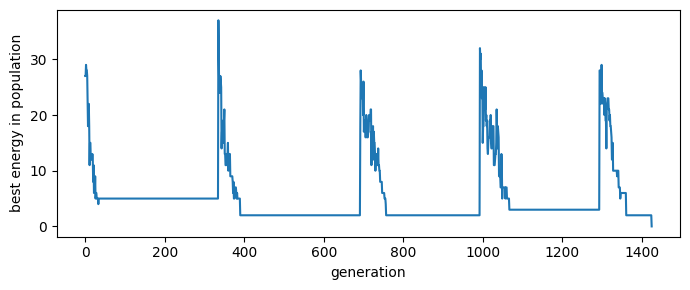

In [17]:
gens, values = zip(*r["history"])
plt.figure(figsize=(7, 3))
plt.plot(gens, values)
plt.xlabel("generation")
plt.ylabel("best energy in population")
plt.tight_layout()
plt.savefig("ga_energy.png", dpi=150)
plt.show()


## Experiment 3b
Sizes N = 3–8, 10, 12, 15 and 20 (the same for the three methods), with and without givens, 9 runs each, 10 seconds per run.

In [18]:
#one generation costs o(k n^3); the large sizes are kept anyway,
#to see where the ga stops
sizes = [3, 4, 5, 6, 7, 8, 10, 12, 15, 20]
given_fractions = [0.0, 0.2]
puzzle_seeds = range(3)
run_seeds = range(3)
time_limit = 10


In [19]:
rows = []
for n in sizes:
    for frac in given_fractions:
        for p in puzzle_seeds:
            puzzle = make_puzzle(n, n_given=int(frac * n * n), seed=p)
            for s in run_seeds:
                r = genetic_algorithm(puzzle, time_limit=time_limit,
                                      seed=1000 + 10 * p + s)
                ok = r["status"] == "solved" and \
                     bool(np.all((puzzle == 0) | (puzzle == r["square"])))
                rows.append({"N": n, "givens": frac, "puzzle": p, "run": s,
                             "solved": ok, "time": r["time"],
                             "generations": r["generations"],
                             "restarts": r["restarts"], "best_energy": r["energy"]})
    print("N =", n, "done")


N = 3 done
N = 4 done
N = 5 done
N = 6 done
N = 7 done
N = 8 done
N = 10 done
N = 12 done
N = 15 done
N = 20 done


In [20]:
results = pd.DataFrame(rows)
results.to_csv("results_ga.csv", index=False)


## Results table

In [21]:
summary = results.groupby(["givens", "N"]).agg(
    solved=("solved", "mean"),
    median_time=("time", "median"),
    median_generations=("generations", "median"),
    median_best_energy=("best_energy", "median")).reset_index()
summary["solved"] = (100 * summary["solved"]).round().astype(int)
summary["median_time"] = summary["median_time"].round(3)
summary


,givens,N,solved,median_time,median_generations,median_best_energy
0,0.0,3,100,0.031,21.0,0.0
1,0.0,4,100,1.172,722.0,0.0
2,0.0,5,22,10.001,5197.0,2.0
3,0.0,6,0,10.001,4376.0,3.0
4,0.0,7,0,10.001,3699.0,63.0
5,0.0,8,0,10.002,3165.0,150.0
6,0.0,10,0,10.002,2303.0,431.0
7,0.0,12,0,10.003,1720.0,962.0
8,0.0,15,0,10.005,1198.0,2386.0
9,0.0,20,0,10.008,643.0,7712.0


## Plot

In [22]:
results = pd.read_csv("results_ga.csv")
summary = results.groupby(["givens", "N"]).agg(
    solved=("solved", "mean"),
    median_best_energy=("best_energy", "median")).reset_index()
summary["solved"] = 100 * summary["solved"]


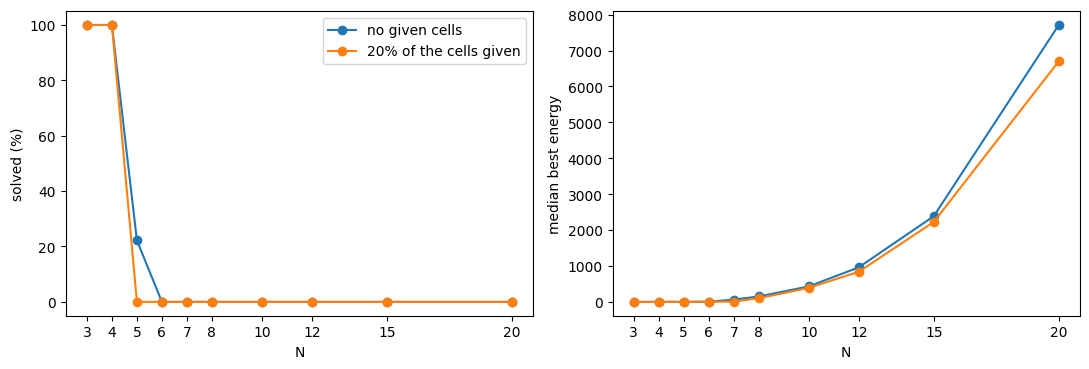

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for frac, g in summary.groupby("givens"):
    label = "no given cells" if frac == 0 else "20% of the cells given"
    axes[0].plot(g["N"], g["solved"], marker="o", label=label)
    #best energy shows how close the GA got when it did not solve
    axes[1].plot(g["N"], g["median_best_energy"], marker="o", label=label)
axes[0].set_ylabel("solved (%)")
axes[0].set_ylim(-5, 105)
axes[1].set_ylabel("median best energy")
for ax in axes:
    ax.set_xlabel("N")
    ax.set_xticks(sizes)
axes[0].legend()
plt.tight_layout()
plt.savefig("ga_results.png", dpi=150)
plt.show()


## Correctness checks
Special cases and an independent check of every returned square (time limit 2 s).

In [24]:
def valid_square(square, puzzle):
    #written without get_lines, so it does not share code with the solver
    sq = np.array(square)
    puzzle = np.array(puzzle)
    n = len(sq)
    M = n * (n * n + 1) // 2
    values_ok = sorted(sq.flatten().tolist()) == list(range(1, n * n + 1))
    lines_ok = (all(sq.sum(axis=0) == M) and all(sq.sum(axis=1) == M)
                and np.trace(sq) == M and np.trace(np.fliplr(sq)) == M)
    givens_ok = bool(np.all((puzzle == 0) | (puzzle == sq)))
    return values_ok and lines_ok and givens_ok

In [25]:
full = make_puzzle(4, n_given=16, seed=0)
one_empty = full.copy()
one_empty[0, 0] = 0
two_empty = one_empty.copy()
two_empty[3, 2] = 0
cases = {
    "repeated given": [[1, 1, 0], [0, 0, 0], [0, 0, 0]],
    "given out of range": [[10, 0, 0], [0, 0, 0], [0, 0, 0]],
    #the centre of a 3x3 magic square is always 5, so this has no solution
    "impossible givens": [[0, 0, 0], [0, 1, 0], [0, 0, 0]],
    "complete square": full,
    "1 empty cell": one_empty,
    "2 empty cells": two_empty,
}

In [26]:
for name, p in cases.items():
    r = genetic_algorithm(p, time_limit=2)
    valid = r["square"] is not None and valid_square(r["square"], p)
    print(f"{name:20s} {r['status']:14s} {r['time']:5.2f} s   valid square: {valid}")

repeated given       invalid input   0.00 s   valid square: False
given out of range   invalid input   0.00 s   valid square: False
impossible givens    timeout         2.00 s   valid square: False
complete square      solved          0.00 s   valid square: True
1 empty cell         solved          0.00 s   valid square: True
2 empty cells        solved          0.00 s   valid square: True


In [27]:
#every solved square on random puzzles goes through the independent check
runs, checked, wrong = 0, 0, 0
for n in [3, 4]:
    for frac in [0.0, 0.2]:
        for seed in range(5):
            p = make_puzzle(n, n_given=int(frac * n * n), seed=seed)
            r = genetic_algorithm(p, time_limit=2)
            runs += 1
            if r["status"] == "solved":
                checked += 1
                wrong += not valid_square(r["square"], p)
print(f"{checked} of {runs} runs solved, {wrong} wrong squares")

17 of 20 runs solved, 0 wrong squares
